## ToDo:

- x change core so that perturbation can be added piece wise
- x write method for noise
- x write method for background trend
- o figure out how to store perturbation information for reproducibility
- o adapt testing
- o adapt tutorial

In [1]:
from ponds import PONDS

pd = PONDS(
    lat_size=50,
    lon_size=50,
    time_size=100,
)

pd.data

<xarray.Dataset> Size: 2MB
Dimensions:  (time: 100, lat: 50, lon: 50)
Coordinates:
  * time     (time) float64 800B 0.0 1.0 2.0 3.0 4.0 ... 96.0 97.0 98.0 99.0
  * lat      (lat) float64 400B -90.0 -86.33 -82.65 -78.98 ... 82.65 86.33 90.0
  * lon      (lon) float64 400B -180.0 -172.7 -165.3 ... 165.3 172.7 180.0
Data variables:
    ts       (time, lat, lon) float64 2MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
Attributes:
    cluster_key:  c

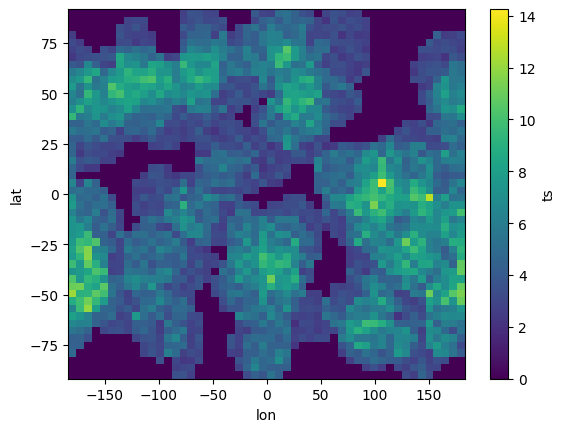

In [8]:
from ponds import PONDS, WhiteNoise, GAUSS, Trend

pd = PONDS(
    lat_size=50,
    lon_size=50,
    time_size=100,
)


for i in range(70):
    pd.add_perturbation(
        perturbation_method=WhiteNoise(
            magnitude=1,
            random_seed=i,
        ),
        shape_method=GAUSS(random_seed=i),
    )

    pd.add_perturbation(
        perturbation_method=Trend(),
        shape_method=GAUSS(random_seed=i),
    )

pd.data

#pd.data.ts.plot()
pd.data.ts.max(dim="time").plot()

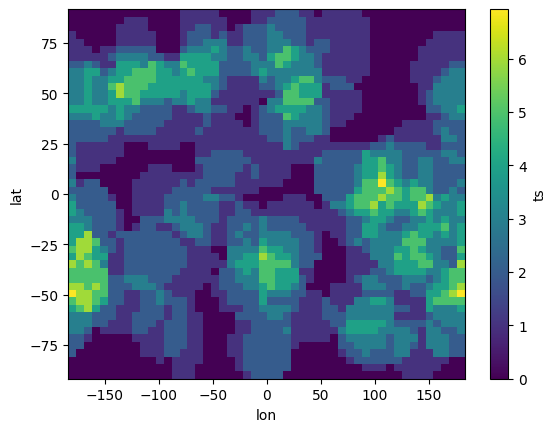

In [12]:
from ponds import PONDS, WhiteNoise, GAUSS, Trend

pd = PONDS(
    lat_size=50,
    lon_size=50,
    time_size=100,
)


for i in range(70):
    #pd.add_perturbation(
    #    perturbation_method=WhiteNoise(
    #        magnitude=1,
    #        random_seed=i,
    #    ),
    #    shape_method=GAUSS(random_seed=i),
    #)

    pd.add_perturbation(
        perturbation_method=Trend(),
        shape_method=GAUSS(random_seed=i),
    )

pd.data

#pd.data.ts.plot()
pd.data.ts.max(dim="time").plot()